# 18b · Clusters are hypotheses to inspect

## The engineering question
Are clusters stable semantic groupings, or artifacts of k, initialization, and a two-dimensional projection?

**Learning outcomes:** cluster real embeddings; compare initialization stability and silhouette diagnostics; inspect representative source examples; distinguish a projection from the original distance space.

We use the twelve fictional support training sentences as an unlabeled exploratory corpus. K-means minimizes squared Euclidean distance to centroids. On normalized points, pairwise squared distance relates to cosine, but unconstrained centroid updates do not make ordinary k-means identical to spherical k-means. We compare k=2,3,4 and five seeds with one initialization each so instability can remain visible.

Silhouette is computed in the original embedding space. PCA is only a display projection; apparent two-dimensional gaps are not a clustering validity test. The known support labels are not used to fit or select the clusters.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("18b", "B", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
import json

fixtures = json.loads((root() / "datasets/applications.json").read_text())

,k,seed,silhouette,ARI_vs_seed0
0,2,0,0.262594,1.000000
1,2,1,0.211923,0.667278
2,2,2,0.262594,1.000000
3,2,3,0.211923,0.667278
4,2,4,0.211923,0.667278
5,3,0,0.323788,1.000000
6,3,1,0.323788,1.000000
7,3,2,0.323788,1.000000
8,3,3,0.323788,1.000000
9,3,4,0.323788,1.000000


,example,text,cluster
0,0,The invoice includes a duplicate charge,2
1,1,Please refund the annual subscription payment,2
2,2,Our credit card payment was declined,2
3,3,The renewal price is incorrect,2
4,4,I cannot sign in with my password,0
5,5,My login verification code expired,0
6,6,Please restore access to my locked account,0
7,7,The single sign on login failed,0
8,8,The router loses internet connectivity,1
9,9,Ethernet packets are dropping between switches,1


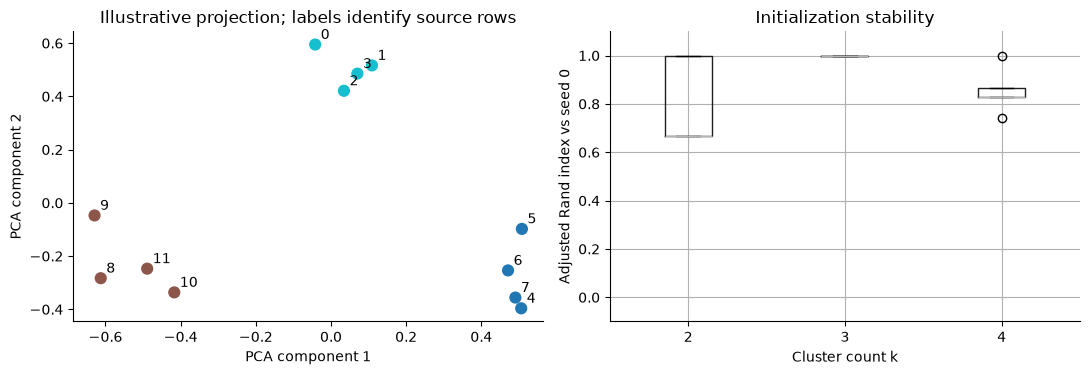

In [3]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from vector_masterclass.models import embed

texts = [t for t, l in fixtures["classification"]["train"]]
vectors = embed(texts)
rows, assignments = [], {}
for k in [2, 3, 4]:
    for seed in range(5):
        labels = KMeans(n_clusters=k, random_state=seed, n_init=1).fit_predict(vectors)
        assignments[k, seed] = labels
        rows.append(
            {
                "k": k,
                "seed": seed,
                "silhouette": silhouette_score(vectors, labels, metric="cosine"),
                "ARI_vs_seed0": adjusted_rand_score(assignments[k, 0], labels),
            }
        )
results = lesson.table(pd.DataFrame(rows))
display(results)
# Display k=3 for the declared teaching example; do not select by known labels.
labels = assignments[3, 0]
projection = PCA(n_components=2, random_state=17).fit_transform(vectors)
members = lesson.table(
    pd.DataFrame({"example": range(len(texts)), "text": texts, "cluster": labels}), "members"
)
display(members)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(projection[:, 0], projection[:, 1], c=labels, cmap="tab10", s=60)
for i, (x, y) in enumerate(projection):
    axes[0].annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points")
axes[0].set(
    xlabel="PCA component 1",
    ylabel="PCA component 2",
    title="Illustrative projection; labels identify source rows",
)
results.boxplot(column="ARI_vs_seed0", by="k", ax=axes[1])
axes[1].set(
    title="Initialization stability",
    ylabel="Adjusted Rand index vs seed 0",
    xlabel="Cluster count k",
    ylim=(-0.1, 1.1),
)
fig.suptitle("")
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Stable clusters can still be irrelevant to a business task; unstable clusters may reflect legitimate overlapping topics. Silhouette rewards geometric separation and can prefer a coarse partition. Read the member texts before naming a cluster, and do not equate a topic cluster with a verified category.

**Exercise:** add one sentence combining billing and login problems. Inspect how membership changes across seeds. Then compare the original-space nearest neighbors with distances in the PCA plot. Explain a case where the projection suggests a relationship that the original vectors do not support.

Production exploration needs deduplication, sampling, language/source slices, drift monitoring, and a plan for human naming and review. Density-based methods or hierarchical clustering may suit another shape; no method removes the need to inspect source examples.

In [4]:
manifest = lesson.finish(
    {
        "all_initializations_measured": len(results) == 15,
        "finite_diagnostics": bool(
            np.isfinite(results[["silhouette", "ARI_vs_seed0"]]).all().all()
        ),
        "projection_labeled_illustrative": projection.shape == (12, 2),
        "source_examples_available": len(members) == 12,
    },
    observations={
        "k_values": [2, 3, 4],
        "seeds": list(range(5)),
        "label_use": "none during fit or cluster-count selection",
        "projection": "PCA display only",
    },
)

{
  "artifact": "artifacts/20261031T060013Z-6b2097/18b",
  "checks": {
    "all_initializations_measured": true,
    "finite_diagnostics": true,
    "projection_labeled_illustrative": true,
    "source_examples_available": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.